<a href="https://colab.research.google.com/github/rifaa05/Project-Akhir_ML_5C_Kelompok-2/blob/main/Varian2_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Silakan pilih file dataset (.csv) untuk diupload:


Saving heart.csv.xls to heart.csv.xls

Dataset 'heart.csv.xls' berhasil dimuat!
Ukuran dataset: 918 baris, 12 kolom


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



Jumlah data training: 734
Jumlah data testing: 184

CLASSIFICATION REPORT K=3
              precision    recall  f1-score   support

 Tidak Sakit       0.91      0.84      0.87        82
       Sakit       0.88      0.93      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184


CLASSIFICATION REPORT K=5
              precision    recall  f1-score   support

 Tidak Sakit       0.88      0.89      0.88        82
       Sakit       0.91      0.90      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184


CLASSIFICATION REPORT K=7
              precision    recall  f1-score   support

 Tidak Sakit       0.91      0.89      0.90        82
       Sakit       0.91      0.93      0.92       102

    accuracy                           0.91      

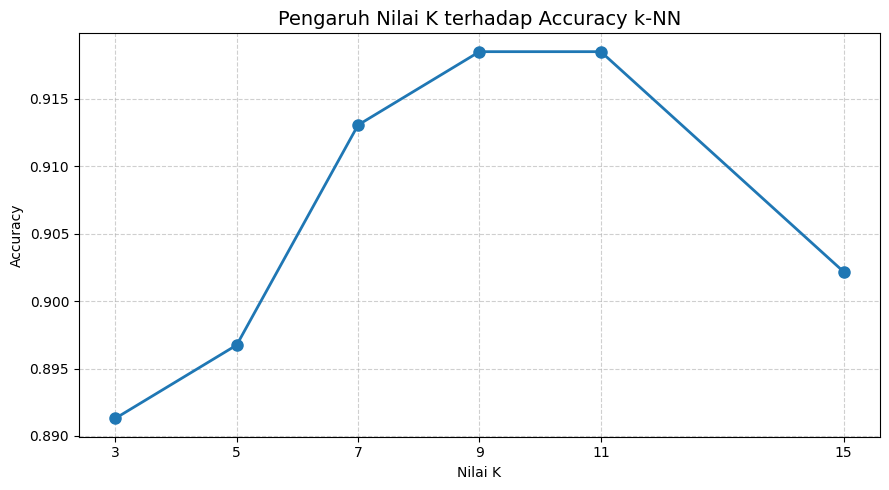

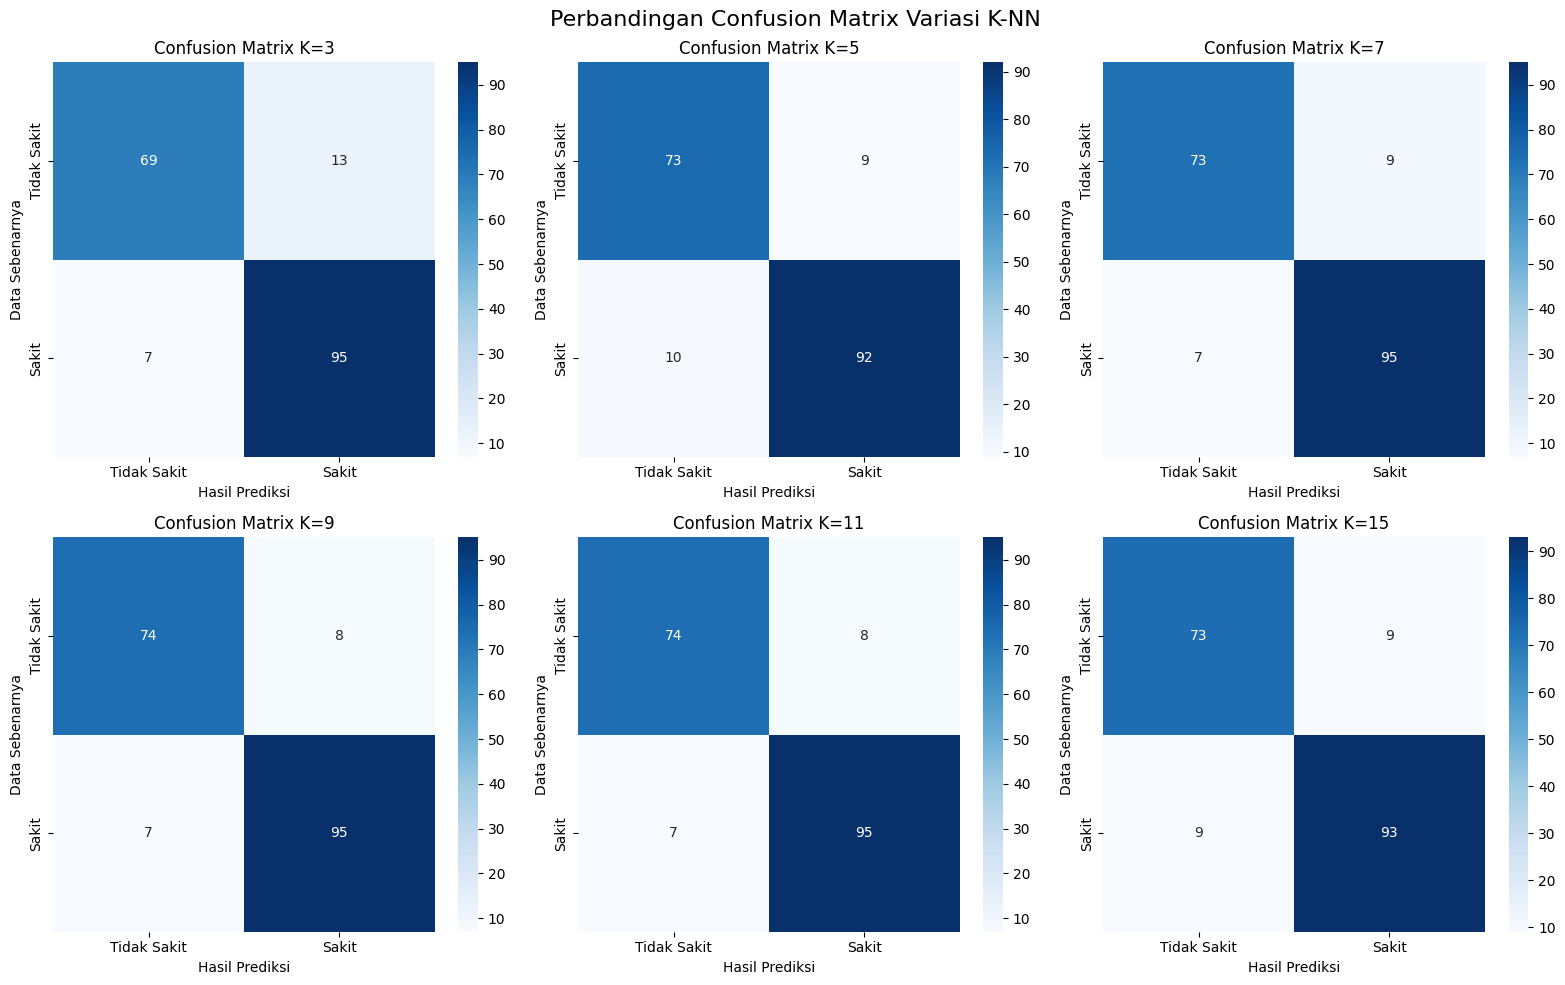


RINGKASAN HASIL EKSPERIMEN K-NN


,Nilai K,Accuracy,Precision,Recall,F1-Score
0,3,89.13%,87.96%,93.14%,90.48%
1,5,89.67%,91.09%,90.20%,90.64%
2,7,91.30%,91.35%,93.14%,92.23%
3,9,91.85%,92.23%,93.14%,92.68%
4,11,91.85%,92.23%,93.14%,92.68%
5,15,90.22%,91.18%,91.18%,91.18%


In [2]:
# =====================================================
# 1. IMPORT LIBRARY
# =====================================================
import io
from google.colab import files
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# =====================================================
# 2. UPLOAD & LOAD DATASET
# =====================================================
print("Silakan pilih file dataset (.csv) untuk diupload:")
uploaded = files.upload()

# Mengambil nama file yang diupload secara otomatis
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f"\nDataset '{filename}' berhasil dimuat!")
print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
display(df.head())


# =====================================================
# 3. MEMISAHKAN FITUR DAN TARGET
# =====================================================
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]


# =====================================================
# 4. MENENTUKAN FITUR NUMERIK DAN KATEGORIK
# =====================================================
numerical_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak",
]

categorical_features = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope",
]


# =====================================================
# 5. PREPROCESSING DATA
# =====================================================
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)


# =====================================================
# 6. MEMBAGI DATA TRAINING DAN TESTING
# =====================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nJumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])


# =====================================================
# 7. EKSPERIMEN VARIASI NILAI K
# =====================================================
daftar_k = [3, 5, 7, 9, 11, 15]

hasil_evaluasi = []
confusion_matrices = {}

for k in daftar_k:
  # Membuat pipeline model
  model = Pipeline([
      ("preprocessing", preprocessor),
      ("knn", KNeighborsClassifier(n_neighbors=k)),
  ])

  # Melatih model
  model.fit(X_train, y_train)

  # Prediksi data testing
  y_pred = model.predict(X_test)

  # Menghitung metrik evaluasi
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  recall = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)

  # Menyimpan hasil evaluasi
  hasil_evaluasi.append({
      "Nilai K": k,
      "Accuracy": accuracy,
      "Precision": precision,
      "Recall": recall,
      "F1-Score": f1,
  })

  # Menyimpan confusion matrix
  confusion_matrices[k] = confusion_matrix(y_test, y_pred)

  # Menampilkan classification report
  print(f"\nCLASSIFICATION REPORT K={k}")
  print(
      classification_report(
          y_test, y_pred, target_names=["Tidak Sakit", "Sakit"], zero_division=0
      )
  )


# =====================================================
# 8. MENAMPILKAN TABEL HASIL EVALUASI
# =====================================================
hasil_df = pd.DataFrame(hasil_evaluasi)

print("\n==========================================")
print("TABEL PERBANDINGAN HASIL VARIASI NILAI K")
print("==========================================")
print(hasil_df.round(4).to_string(index=False))


# =====================================================
# 9. MENENTUKAN NILAI K TERBAIK
# =====================================================
nilai_tertinggi = hasil_df["Accuracy"].max()
model_terbaik = hasil_df[hasil_df["Accuracy"] == nilai_tertinggi]

print("\n==========================================")
print("HASIL PARAMETER TERBAIK")
print("==========================================")
print("Accuracy tertinggi:", round(nilai_tertinggi, 4))
print("Nilai K terbaik:", model_terbaik["Nilai K"].tolist())
print("F1-Score:", model_terbaik["F1-Score"].tolist())


# =====================================================
# 10. VISUALISASI GRAFIK ACCURACY
# =====================================================
plt.figure(figsize=(9, 5))

plt.plot(
    hasil_df["Nilai K"],
    hasil_df["Accuracy"],
    marker="o",
    linewidth=2,
    markersize=8,
)

plt.title("Pengaruh Nilai K terhadap Accuracy k-NN", fontsize=14)
plt.xlabel("Nilai K")
plt.ylabel("Accuracy")
plt.xticks(daftar_k)
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


# =====================================================
# 11. VISUALISASI SEMUA CONFUSION MATRIX
# =====================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, k in enumerate(daftar_k):
  cm = confusion_matrices[k]

  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      xticklabels=["Tidak Sakit", "Sakit"],
      yticklabels=["Tidak Sakit", "Sakit"],
      ax=axes[i],
  )

  axes[i].set_title(f"Confusion Matrix K={k}")
  axes[i].set_xlabel("Hasil Prediksi")
  axes[i].set_ylabel("Data Sebenarnya")

plt.suptitle("Perbandingan Confusion Matrix Variasi K-NN", fontsize=16)
plt.tight_layout()
plt.show()


# =====================================================
# 12. TABEL RINGKASAN HASIL EKSPERIMEN
# =====================================================
print("\n==========================================")
print("RINGKASAN HASIL EKSPERIMEN K-NN")
print("==========================================")

display(
    hasil_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}",
    })
)